Dataset URL: https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud
License(s): DbCL-1.0
100% 66.0M/66.0M [00:00<00:00, 141MB/s]

Dataset Shape: (284807, 31)
   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.1083

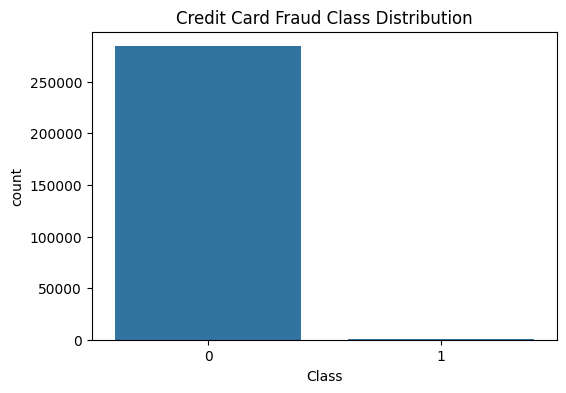

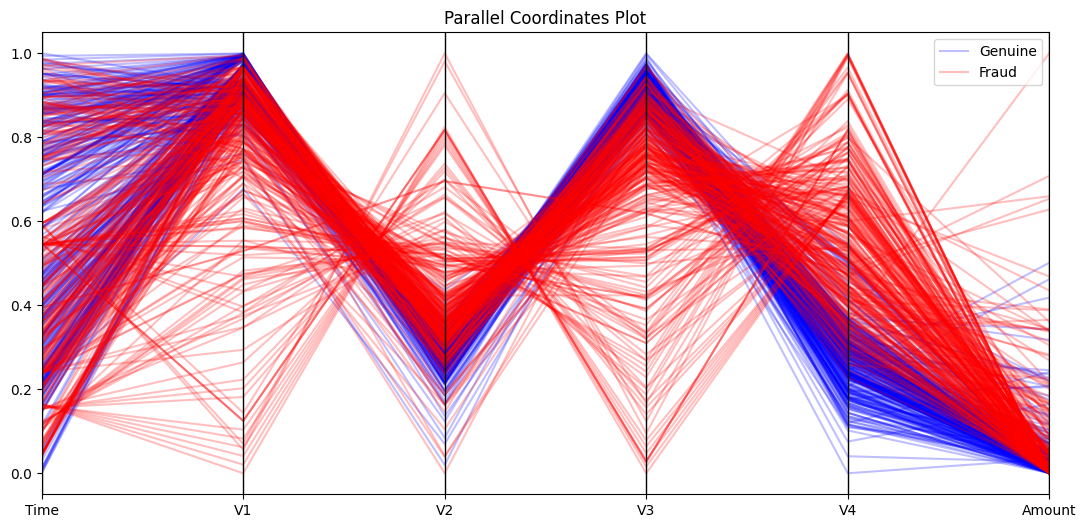

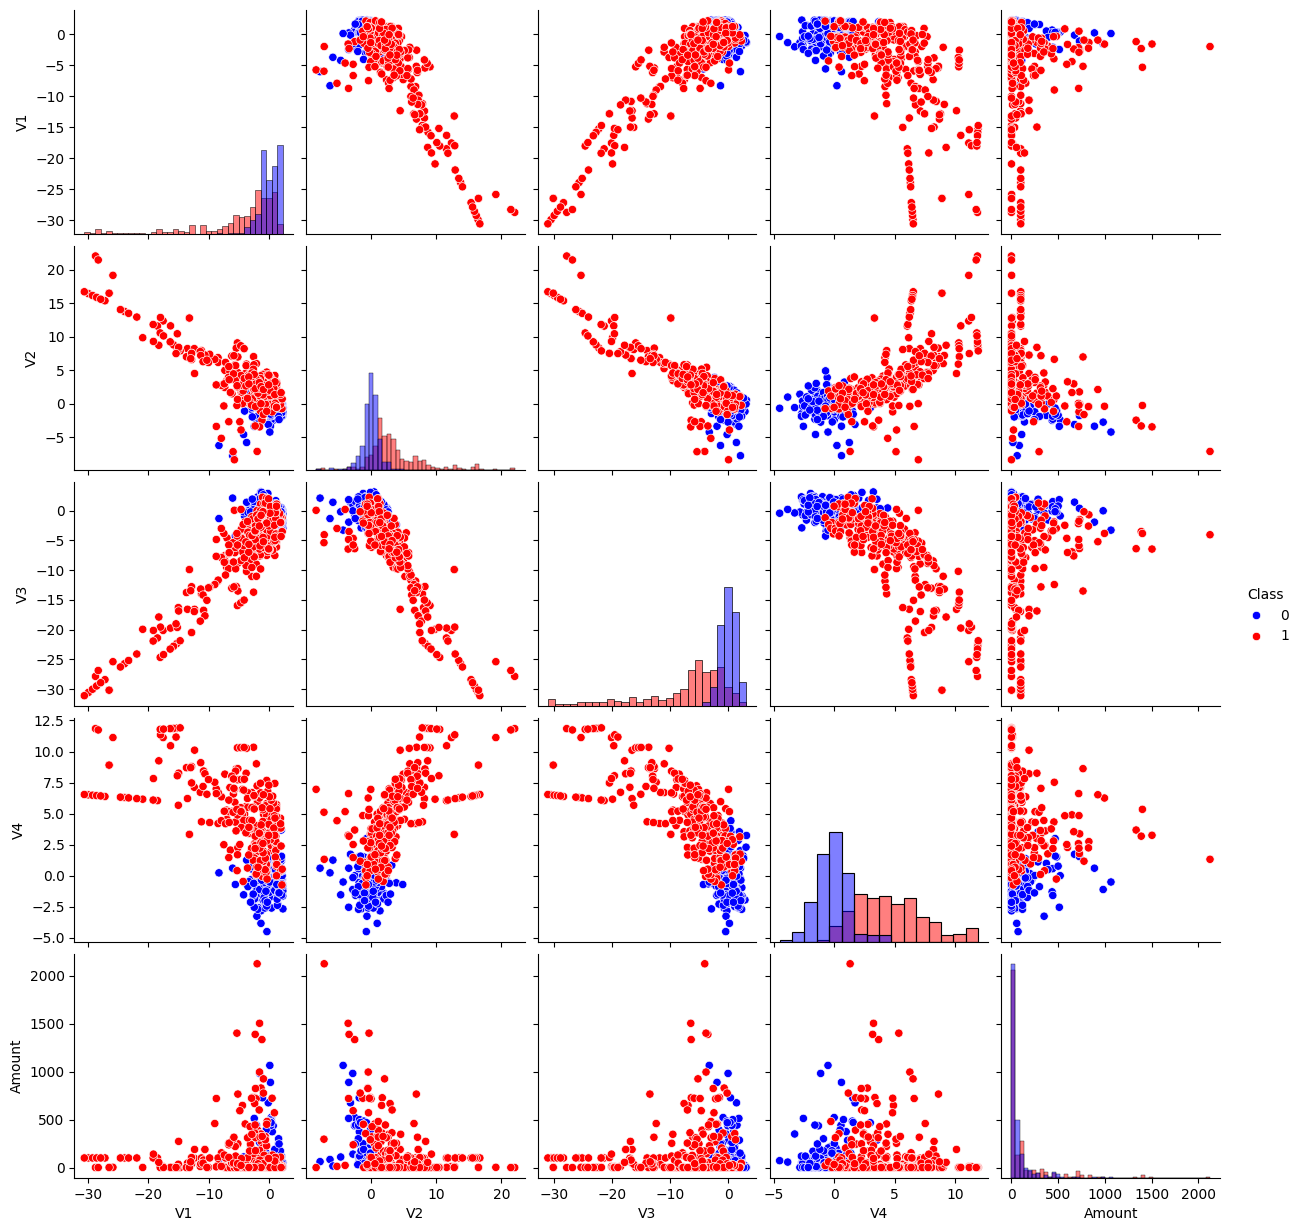

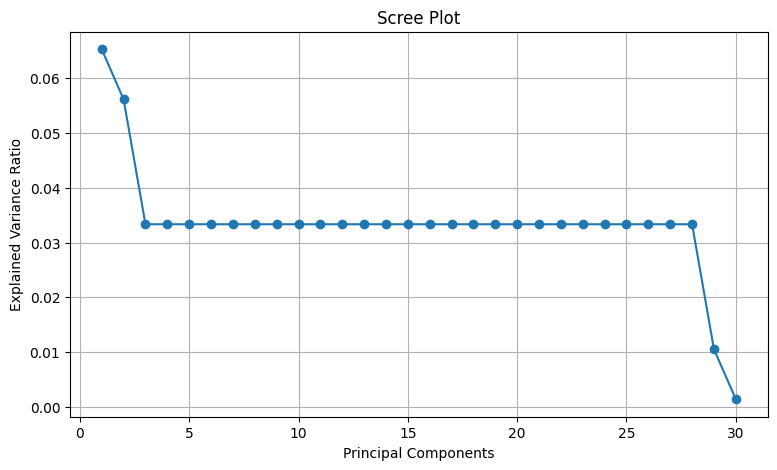

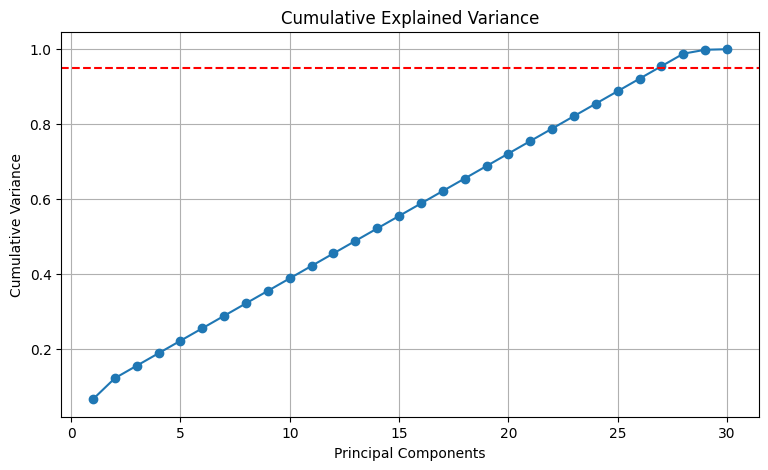

Components for 95% variance: 27


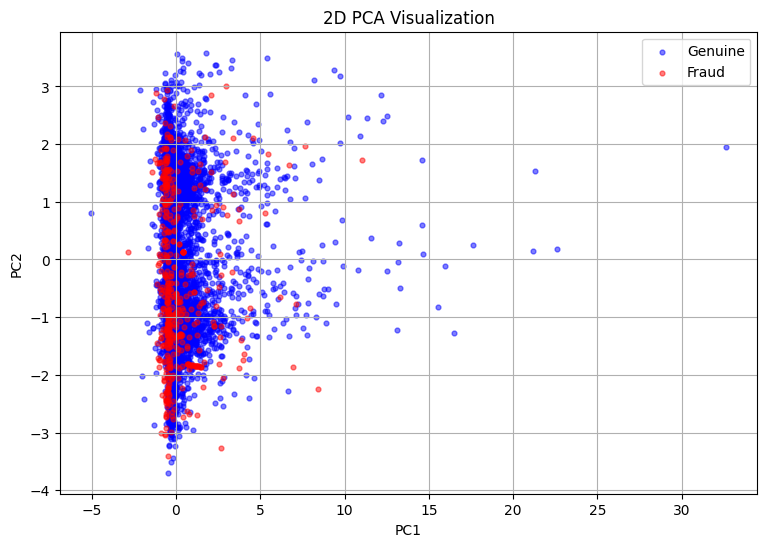

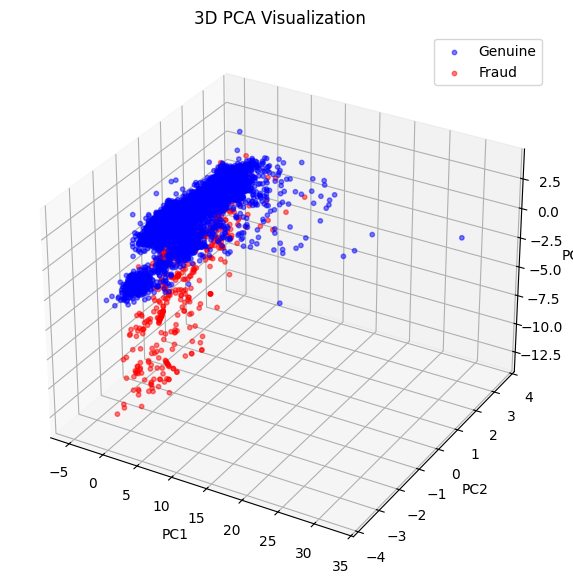


All PCA and visualization tasks completed!


In [1]:
!pip install -q kaggle pandas numpy matplotlib seaborn scikit-learn

import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from pandas.plotting import parallel_coordinates

# 1. Download dataset directly using Kaggle CLI
!kaggle datasets download mlg-ulb/creditcardfraud

# 2. Extract dataset
os.makedirs("creditcard_data", exist_ok=True)

with zipfile.ZipFile("creditcardfraud.zip", "r") as z:
    z.extractall("creditcard_data")

# 3. Load dataset
csv_file = glob.glob("creditcard_data/*.csv")[0]
df = pd.read_csv(csv_file)

print("Dataset Shape:", df.shape)
print(df.head())

# 4. Preprocessing
X = df.drop("Class", axis=1)
y = df["Class"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Class distribution
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Class")
plt.title("Credit Card Fraud Class Distribution")
plt.show()

# 6. Parallel Coordinates Plot
sample = df.groupby("Class", group_keys=False).sample(
    n=300, random_state=42
)

features = ["Time", "V1", "V2", "V3", "V4", "Amount"]
parallel_df = sample[features + ["Class"]].copy()

for col in features:
    parallel_df[col] = (
        (parallel_df[col] - parallel_df[col].min()) /
        (parallel_df[col].max() - parallel_df[col].min() + 1e-9)
    )

parallel_df["Class"] = parallel_df["Class"].map({
    0: "Genuine", 1: "Fraud"
})

plt.figure(figsize=(13,6))
parallel_coordinates(
    parallel_df, "Class",
    color=["blue", "red"], alpha=0.25
)
plt.title("Parallel Coordinates Plot")
plt.grid()
plt.show()

# 7. Scatterplot Matrix
scatter_df = df.groupby("Class", group_keys=False).sample(
    n=300, random_state=42
)

sns.pairplot(
    scatter_df,
    vars=["V1", "V2", "V3", "V4", "Amount"],
    hue="Class",
    palette={0:"blue", 1:"red"},
    diag_kind="hist"
)
plt.show()

# 8. PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

variance = pca.explained_variance_ratio_

# 9. Scree Plot
plt.figure(figsize=(9,5))
plt.plot(range(1,31), variance, marker="o")
plt.title("Scree Plot")
plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.grid()
plt.show()

# 10. Cumulative Explained Variance
cumulative = np.cumsum(variance)

plt.figure(figsize=(9,5))
plt.plot(range(1,31), cumulative, marker="o")
plt.axhline(0.95, color="red", linestyle="--")
plt.title("Cumulative Explained Variance")
plt.xlabel("Principal Components")
plt.ylabel("Cumulative Variance")
plt.grid()
plt.show()

print("Components for 95% variance:",
      np.argmax(cumulative >= 0.95) + 1)

# 11. Select visualization samples
rng = np.random.RandomState(42)
fraud_idx = np.where(y.to_numpy() == 1)[0]
genuine_idx = np.where(y.to_numpy() == 0)[0]

genuine_sample = rng.choice(
    genuine_idx, min(10000, len(genuine_idx)),
    replace=False
)

indices = np.concatenate([genuine_sample, fraud_idx])
labels = y.iloc[indices].to_numpy()

# 12. 2D PCA
pca2 = PCA(n_components=2)
X2 = pca2.fit_transform(X_scaled)

plt.figure(figsize=(9,6))
for c, color, name in [(0,"blue","Genuine"),(1,"red","Fraud")]:
    mask = labels == c
    plt.scatter(
        X2[indices[mask],0],
        X2[indices[mask],1],
        c=color, label=name, alpha=0.5, s=12
    )

plt.title("2D PCA Visualization")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.grid()
plt.show()

# 13. 3D PCA
pca3 = PCA(n_components=3)
X3 = pca3.fit_transform(X_scaled)

fig = plt.figure(figsize=(10,7))
ax = fig.add_subplot(111, projection="3d")

for c, color, name in [(0,"blue","Genuine"),(1,"red","Fraud")]:
    mask = labels == c
    ax.scatter(
        X3[indices[mask],0],
        X3[indices[mask],1],
        X3[indices[mask],2],
        c=color, label=name, alpha=0.5, s=10
    )

ax.set_title("3D PCA Visualization")
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.legend()
plt.show()

print("\nAll PCA and visualization tasks completed!")




